# Core body temperature estimation for the heat-strain vest

Estimates core temperature $\hat{T}_c$ from the values the ESP32 uploads to Firebase
(`heart_rate`, `skin_temp`, `outside_temp`, `feels_like_temp`), then converts it to a risk level
and the Physiological Strain Index (PSI).

| Section | Content |
|---|---|
| Step 0 | Data inspection (PROSPIE + firefighters) |
| Step 1 | Target and risk levels |
| Step 2 | Feature table (shared `features.py`) |
| Step 3 | Baselines: constant, ECTemp, linear HR + $T_{sk}$ |
| Step 4 | Ridge, LightGBM, hybrids with ECTemp |
| Step 5 | Nested leave-one-subject-out validation, robustness, external test |
| Step 6 | Interpretation (SHAP, plots, lag) |
| Save | Final model for `service.py` |

All feature code lives in **`features.py`**, which `service.py` imports too.

In [1]:
import warnings, json, time
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge, LinearRegression
from sklearn.model_selection import GridSearchCV, GroupKFold
import lightgbm as lgb
import shap
import features as F

warnings.filterwarnings("ignore")
SEED = 42
rng = np.random.default_rng(SEED)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
DATA = Path("data"); FIG = Path("figures"); RES = Path("results"); MOD = Path("models")
for p in (FIG, RES, MOD): p.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
print("features.py version", F.FEATURE_VERSION)

features.py version 1.0


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 0 – Inspect the data

### 0.1 PROSPIE (Loughborough)
Sheet `Data`: one row per **minute** per trial. `9999` = missing (stated in the `Key` sheet).
Values shown in red in the original file were already interpolated by the authors over gaps of at most 5 min.

In [2]:
COLS = ['cond','time','act','pid','sex','age','mass','height','bodyfat','vo2peak','acclim','trained','clothing',
        'rh','tamb','wind','t_front','rh_front','t_back','rh_back','workrest','vo2work','speed','grade','solar',
        'sol1','sol2','sol3','sweat_L','tre','dtre',
        'sk_abdomen','sk_calf','sk_chest','sk_foot','sk_hand','sk_head','sk_lowerarm','sk_lowerback','sk_thigh',
        'sk_upperarm','sk_upperback','ins_skin','ins_tamb','br','hr','hrtype','ts','tc','tp','sw','rpe']
raw = pd.read_excel(DATA/"prospie.xlsx", sheet_name="Data", header=None, skiprows=2)
raw = raw.iloc[:, :len(COLS)]; raw.columns = COLS
raw = raw.replace(9999, np.nan)
raw["t_min"] = raw["time"].apply(lambda t: t.hour*60 + t.minute + t.second/60)
raw["trial"] = raw["pid"].astype(int).astype(str) + "_c" + raw["cond"].astype(int).astype(str)
raw["cohort"] = np.where(raw["pid"] <= 18, "A (subj 1-18, cond 1-3)", "B (subj 29-50, cond 6-11)")

print("rows:", len(raw), "| subjects:", raw.pid.nunique(), "| trials:", raw.trial.nunique())
steps = raw.groupby("trial").t_min.apply(lambda s: np.unique(np.diff(s)).tolist())
print("time step inside every trial (min):", sorted({x for v in steps for x in v}))
dur = raw.groupby(["cohort","trial"]).size().groupby("cohort").describe()[["count","mean","min","max"]]
print("\nTrial duration (min) per cohort:"); display(dur)
print("Conditions per cohort:", raw.groupby("cohort").cond.unique().to_dict())
cond = pd.read_excel(DATA/"prospie.xlsx", sheet_name="Conditions ", header=1).dropna(how="all")
display(cond)

rows: 17264 | subjects: 40 | trials: 155
time step inside every trial (min): [1.0]

Trial duration (min) per cohort:


,count,mean,min,max
cohort,,,,
"A (subj 1-18, cond 1-3)",53.0,117.735849,48.0,136.0
"B (subj 29-50, cond 6-11)",102.0,108.078431,36.0,141.0


Conditions per cohort: {'A (subj 1-18, cond 1-3)': array([1, 2, 3]), 'B (subj 29-50, cond 6-11)': array([ 6,  7,  8,  9, 10, 11])}


,Condition,Ambient Temperature/rh/ WBGT/ WVP/clothing/solar radiation,Work Pattern,Heat stress scenario
0,1,"40°C, 35 %, 31.85°C, 17.90g.m-3, Permeable, no...",10 minutes rest seated rest in climatic chambe...,"Indoors in a hot factory, basic level PPE."
1,2,"33°C, 85 %, 30.12°C, 30.45g.m-3, Permeable, no...",Same as condition 1,"Indoors in a hot, humid environment. Basic lev..."
2,3,"40°C, 35 %, 31.85°C, 17.90g.m-3, Permeable, no...",2×work cycle* seperated by 10 min seated rest ...,"Indoors in a hot factory, basic level PPE. Int..."
3,6,"25°C, 50 %, 20.95°C, 11.54g.m-3, Impermeable, ...","10 minutes rest, 40 minutes treadmill walking,...","Indoors, cool conditions, PPE."
4,7,"40°C, 20 %, 29.45°C, 10.21g.m-3,Permeable, no ...",Same as condition 6,"Indoors in a hot factory, basic level PPE."
5,8,"40°C, 20 %, 29.45°C, 10.21g.m-3, Impermeable, ...",Same as condition 6,"Indoors in a hot factory, PPE."
6,9,"30°C, 35 %, 28.75°C, 10.68g.m-3, Permeable, so...",Same as condition 6,"Outdoors on a hot sunny day, basic level PPE."
7,10,"40°C, 20 %, 29.13°C, 10.21g.m-3, Permeable, so...",Same as condition 6,"Desert environment, basic level PPE."
8,11,"40°C, 35 %, 31.85°C, 17.90g.m-3,Permeable, no ...",Same as condition 1,"Indoor in a hot factory, basic level PPE."


In [3]:
skin_sites = [c for c in COLS if c.startswith("sk_")] + ["ins_skin"]
show = ["tre","hr","tamb","rh"] + skin_sites + ["t_back","rh_back"]
miss = raw.groupby("cohort")[show].apply(lambda g: g.isna().mean()*100).T.round(1)
miss.columns = [c.split(" ")[0] + " missing %" for c in miss.columns]
display(miss)
print("HR measurement method per cohort (1 = finger PPG, 2 = Equivital chest, 3 = Polar chest):")
display(raw.groupby("cohort").hrtype.value_counts().unstack().fillna(0).astype(int))
gaps = raw.dropna(subset=["hr"]).groupby("trial").t_min.apply(lambda s: np.median(np.diff(s)) if len(s) > 1 else np.nan)
print("Median spacing between HR values (min):",
      gaps.groupby(raw.groupby("trial").cohort.first()).median().to_dict())

,A missing %,B missing %
tre,0.2,0.5
hr,79.5,3.2
tamb,0.1,2.1
rh,0.1,2.1
sk_abdomen,1.2,7.0
sk_calf,1.8,10.1
sk_chest,1.1,5.2
sk_foot,0.0,0.0
sk_hand,0.9,9.3
sk_head,3.3,3.8


HR measurement method per cohort (1 = finger PPG, 2 = Equivital chest, 3 = Polar chest):


hrtype,1.0,2.0,3.0
cohort,,,
"A (subj 1-18, cond 1-3)",671,24,587
"B (subj 29-50, cond 6-11)",0,11024,0


Median spacing between HR values (min): {'A (subj 1-18, cond 1-3)': 5.0, 'B (subj 29-50, cond 6-11)': 1.0}


**What the inspection shows**

* **Core temperature:** only rectal temperature (`Corerectal`, °C, 1 min). `Δcore` is the change from trial start, it is not used.
* **Skin sites (iButtons, right side):** abdomen, calf, chest, foot, hand, head, lower arm, lower back, thigh, upper arm, **upper back**,
  plus **`Ins skin`: an insulated thermistor at C7–T2** (covered by a 5 × 5 × 1 cm foam block) and `Tamb`, the microclimate on the outside of that foam.
* **Environment:** `Humidity` / `Temp` = true chamber air (or the ~22 °C cooling area during the mid-trial rest). Separate columns hold the
  clothing microclimate (front and back). **True ambient exists, so it is used as `outside_temp`.**
* **Two cohorts with different HR recording:**
  * **Cohort A** (subjects 1–18, conditions 1–3): HR is a spot reading about **every 5 min** (mostly finger PPG, some Polar),
    so after the 5-min carry-forward it is a step signal; minute-level slopes are much coarser than in cohort B.
  * **Cohort B** (subjects 29–50, conditions 6–11): **continuous** chest-strap HR (Equivital), 3 % missing.

**Decision:** the HR-based models are trained and validated (LOSO) on **cohort B**. Cohort A is held out completely and used once at the end as
an **external test**: new people, new heat conditions, a different HR sensor (finger PPG, closer to your vest's PPG than a chest strap) and coarse 5-min HR.

### 0.2 Firefighters dataset (Mendeley, Mauvieux et al. 2025)

In [4]:
ff = pd.read_excel(DATA/"firefighters.xlsx", sheet_name=None, header=None)
for name, df in ff.items():
    print(f"{name!r:35} {df.shape}")
tc_ff = ff["AM PM Tcore"]
print("\n'AM PM Tcore' header (time points):", [str(v) for v in tc_ff.iloc[3, 3:12].tolist()], "...")
allc = [str(v) for v in ff["All Data "].iloc[3].dropna().tolist()]
print("'All Data ' variables:", allc)

'All Data '                         (32, 44)
'Results'                           (30, 6)
'Table 1'                           (30, 6)
'Table 2 - Body Mass % Hydro'       (33, 14)
'T° Day Off & Cosonor'              (187, 4)
'AM PM Tcore'                       (98, 67)
'Core temp from rest to 40 min'     (98, 15)
'Slope 0-40 min'                    (22, 7)
'Recovery'                          (59, 55)
'Skin T° AM-PM'                     (9, 8)

'AM PM Tcore' header (time points): ['00:00:00', '00:08:00', '00:16:00', '00:24:00', '00:32:00', '00:40:00', '00:48:00', '00:56:00', '01:04:00'] ...
'All Data ' variables: ['Resting T°core Reference Day Off vs T°core Experimental Day', 'Weight (Kg)', 'Body water percentage (%)', 'HRmax (beat.min-1)', 'HR Mean', 'Perceptual Strain (RPE)', 'T° Thorax -Meam', 'T° Thorax -Max', 'T° Nuque sous Cagoule - Meam', 'T° Nuque sous Cagoule - Max', 'T° Sous EPI - Meam', 'T° Sous EPI - Max', 'Hg Sous EPI - Meam', 'Hg Sous EPI - Max']


**Firefighters verdict: not usable as an external test.** The file holds core temperature every 8 min (gastrointestinal capsule)
and **per-subject summary values** (HR mean and max, mean and max thorax and neck temperature). There is **no heart-rate time series,
no skin-temperature time series and no ambient time series**, so none of the model inputs can be reconstructed minute by minute.
A reduced-feature model would also be impossible, because even skin temperature exists only as a session mean.

**Adapted external test (replacement):** PROSPIE cohort A (18 subjects never seen in training, conditions 1–3 never seen in training,
5-min spot HR from a finger PPG). This is a genuinely independent group of people and heat scenarios. It is evaluated once, after all choices are fixed.

## Step 1 – Target and risk levels

* Target: rectal temperature $T_c$ (°C), **regression**, one prediction per minute.
* Risk levels from the prediction: Normal $\hat T_c<38.0$, Caution $38.0\le\hat T_c<38.5$, High strain $\hat T_c\ge 38.5$ (`features.risk_level`).
  Metrics are always reported against the **true** 38.5 °C line. Step 5 additionally derives a lower **alarm threshold** on $\hat T_c$
  so that ≥ 80 % of truly hot minutes are caught; the service uses that threshold for `"high"`.
* PSI (Moran 1998): $\text{PSI}=5\frac{T_{c,t}-T_{c,0}}{39.5-T_{c,0}}+5\frac{HR_t-HR_0}{180-HR_0}$, high strain at $\text{PSI}\ge 7$.
  * "True" PSI: measured $T_c$, $T_{c,0}$ = the trial's first rectal value, $HR_0$ = the 5-min baseline.
  * Live / predicted PSI: $\hat T_c$, $T_{c,0}=37.0$ °C (the service has no core measurement), same $HR_0$.

## Step 2 – Feature table

Each trial is one **session** (in the live service: one continuous wear period).
Inputs are mapped to the Firebase keys only:

| Firebase key | PROSPIE column |
|---|---|
| `heart_rate` | `HR` |
| `skin_temp` | **upper back** iButton (primary), `Ins skin` C7–T2 (sensitivity) |
| `outside_temp` | chamber / room air `Temp` |
| `feels_like_temp` | `features.heat_index_c(Temp, Humidity)`, the same Rothfusz code as the firmware |
| `sweat_level` | **not available** in PROSPIE (only whole-trial sweat loss) → excluded |

**Skin site choice.** The vest NTC sits near C7 and is *not* foam-insulated. `upper back` is the closest *uninsulated* site, so it is the primary input.
`Ins skin` is exactly at C7–T2 but foam-insulated, which pushes it towards core temperature; it is used as the sensitivity check
(and tells us whether insulating the NTC would help). Chest is the third candidate.

**Gaps.** The data is already on a 1-min grid. Inputs are only **carried forward** (HR ≤ 5 min, skin ≤ 2 min, ambient ≤ 10 min).
This is causal; linear interpolation across a gap would use future values. The target (rectal temperature) may be interpolated
over ≤ 2 min, because it is not an input. Rows with no target are dropped.

Quantisation to Firebase resolution (0.1 °C, integer bpm) happens inside `build_features`.

In [5]:
def make_table(df, skin_col="sk_upperback", hr_mask=None):
    # hr_mask: optional boolean Series aligned with df; True = HR removed (robustness test)
    out = []
    for trial, g in df.groupby("trial", sort=False):
        g = g.sort_values("t_min")
        s = pd.DataFrame({
            "t_min": g["t_min"].values - g["t_min"].values[0],
            "hr": g["hr"].values,
            "skin": g[skin_col].values,
            "amb": g["tamb"].values,
            "hi": F.heat_index_c(g["tamb"].values, g["rh"].values),
        })
        if hr_mask is not None:
            s.loc[hr_mask.loc[g.index].values, "hr"] = np.nan
        f = F.build_features(s)
        f["y"] = pd.Series(g["tre"].values).interpolate(limit=2, limit_area="inside").values
        f["hr_raw"] = s["hr"].values
        for c in ("pid", "cond", "trial", "cohort", "act", "age", "sex", "mass"):
            f[c] = g[c].values
        f["tc0_true"] = g["tre"].dropna().iloc[0] if g["tre"].notna().any() else np.nan
        out.append(f)
    t = pd.concat(out, ignore_index=True)
    return t

A = raw[raw.pid <= 18]; B = raw[raw.pid >= 29]
TB = make_table(B)
n0 = len(TB)
TB = TB[TB.y.notna()].reset_index(drop=True)
print(f"cohort B rows: {n0}, dropped (no target): {n0-len(TB)}")
EV = ~TB.warming_up          # evaluation rows: after the 5-min baseline (the service is 'warming up' before)
print("evaluation rows:", EV.sum(), "| subjects:", TB.pid.nunique(), "| trials:", TB.trial.nunique())
print(f"minutes with Tc >= 38.0: {(TB.y[EV]>=38).mean()*100:.1f} %   Tc >= 38.5: {(TB.y[EV]>=38.5).mean()*100:.1f} %")
display(TB[F.FEATURES_HYBRID].describe().T[["count","mean","std","min","max"]].round(2))

cohort B rows: 11024, dropped (no target): 28
evaluation rows: 10486 | subjects: 22 | trials: 102
minutes with Tc >= 38.0: 40.2 %   Tc >= 38.5: 12.9 %


,count,mean,std,min,max
hr,10981.0,125.52,30.72,38.00,198.00
skin,10894.0,36.79,1.70,30.10,41.00
amb,10779.0,34.16,7.78,19.00,45.40
hi,10779.0,35.22,9.22,17.80,52.00
t_min,10996.0,55.33,33.37,0.00,120.00
dhr,10981.0,54.38,29.46,-24.40,121.20
dsk,10894.0,2.44,1.75,-3.36,7.38
hr_m5,10888.0,124.45,30.50,40.00,193.80
hr_m10,10588.0,123.99,29.33,40.60,191.40
sk_m5,10802.0,36.75,1.70,30.50,41.00


In [6]:
# Skin-site correlation with rectal temperature (cohort B), for information
cands = ["sk_upperback", "ins_skin", "sk_chest", "sk_lowerback", "sk_head"]
print("Pearson r with rectal temperature (cohort B):")
print(B[cands + ["tre"]].corr()["tre"].drop("tre").round(3).to_string())

Pearson r with rectal temperature (cohort B):
sk_upperback    0.289
ins_skin        0.605
sk_chest        0.428
sk_lowerback    0.373
sk_head         0.272


In [7]:
# PSI agreement on TRUE values
def add_psi(df, yhat=None):
    p_true = F.psi(df.y, df.hr, df.tc0_true, df.hr0)
    out = {"psi_true": p_true}
    if yhat is not None:
        out["psi_pred"] = F.psi(yhat, df.hr, 37.0, df.hr0)
    return pd.DataFrame(out, index=df.index)

ps = add_psi(TB[EV])
hi_tc = TB.y[EV] >= 38.5; hi_psi = ps.psi_true >= 7
print(f"True data: Tc>=38.5 in {hi_tc.mean()*100:.1f}% of minutes, PSI>=7 in {hi_psi.mean()*100:.1f}%")
print(f"Agreement of the two 'high strain' rules: {(hi_tc==hi_psi).mean()*100:.1f}% of minutes")
display(pd.crosstab(hi_tc.rename("Tc>=38.5"), hi_psi.rename("PSI>=7")))

True data: Tc>=38.5 in 12.9% of minutes, PSI>=7 in 8.9%
Agreement of the two 'high strain' rules: 92.7% of minutes


PSI>=7,False,True
Tc>=38.5,,
False,8965,173
True,588,760


## Steps 3–5 – Baselines, models and nested LOSO validation

* **Outer loop:** leave-one-subject-out over the 22 cohort-B subjects. Minutes from one person are never in both train and test.
* **Inner loop:** hyper-parameters are tuned by `GridSearchCV` with `GroupKFold(4)` grouped by subject, on the training subjects only.
  Imputer and scaler sit **inside** the pipeline, so they are fitted per fold.
* **Missing data:** Ridge/linear models impute the training-fold median; LightGBM handles NaN natively; ECTemp skips the
  measurement update for a missing HR minute.
* **Baselines:** constant (mean $T_c$ of the training subjects), ECTemp (published parameters, no training), linear regression on HR + $T_{sk}$.
* **GRU/LSTM: skipped.** 22 subjects / 102 trials (~11 k correlated minutes) is far too little for a recurrent network under LOSO with
  nested tuning; it would overfit and be unstable, and the rolling/EMA features already give the model 5–30 min of history.
  (PyTorch is also not installed in this environment.)

In [8]:
def metrics(y, p, alarm=None):
    y, p = np.asarray(y, float), np.asarray(p, float)
    m = np.isfinite(y) & np.isfinite(p); y, p = y[m], p[m]
    e = p - y
    out = dict(n=len(y), RMSE=np.sqrt(np.mean(e**2)), MAE=np.mean(np.abs(e)), bias=e.mean(),
               LoA_low=e.mean()-1.96*e.std(), LoA_high=e.mean()+1.96*e.std(),
               within_0p3=np.mean(np.abs(e) <= 0.3)*100, within_0p5=np.mean(np.abs(e) <= 0.5)*100)
    th, ph = y >= 38.5, p >= 38.5
    out.update(n_high=int(th.sum()), sens_385=(ph & th).sum()/max(th.sum(), 1)*100,
               prec_385=(ph & th).sum()/max(ph.sum(), 1)*100, missed_high_min=int((th & ~ph).sum()))
    if alarm is not None:
        pa = p >= alarm
        out.update(sens_alarm=(pa & th).sum()/max(th.sum(), 1)*100, prec_alarm=(pa & th).sum()/max(pa.sum(), 1)*100,
                   missed_alarm_min=int((th & ~pa).sum()))
    hm = y >= 38.0
    eh = e[hm]
    out.update(RMSE_hot=np.sqrt(np.mean(eh**2)), MAE_hot=np.mean(np.abs(eh)), bias_hot=eh.mean(),
               within_0p5_hot=np.mean(np.abs(eh) <= 0.5)*100)
    return out

def fit_model(m, X, y, groups):
    # GridSearchCV / ConstantModel take the subject groups (for the inner GroupKFold); plain pipelines do not
    if isinstance(m, (GridSearchCV, ConstantModel)): return m.fit(X, y, groups=groups)
    return m.fit(X, y)

class ConstantModel:
    def fit(self, X, y, groups=None): self.c = float(np.mean(y)); return self
    def predict(self, X): return np.full(len(X), self.c)

def ridge_search():
    pipe = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge())
    return GridSearchCV(pipe, {"ridge__alpha": [0.1, 1, 10, 100, 1000]}, cv=GroupKFold(4),
                        scoring="neg_root_mean_squared_error", n_jobs=1)

def lgb_search():
    est = lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                            reg_lambda=1.0, random_state=SEED, n_jobs=2, verbose=-1)
    grid = {"num_leaves": [7, 15], "min_child_samples": [40, 150]}
    return GridSearchCV(est, grid, cv=GroupKFold(4), scoring="neg_root_mean_squared_error", n_jobs=1)

MODELS = {   # name: (factory, feature list); factory None = ECTemp (no training)
    "Constant":           (ConstantModel, ["t_min"]),
    "ECTemp (HR only)":   (None, ["ectemp"]),
    "Linear HR+Tsk":      (lambda: make_pipeline(SimpleImputer(strategy="median"), LinearRegression()), F.FEATURES_LINEAR_BASELINE),
    "Ridge full":         (ridge_search, F.FEATURES_FULL),
    "LightGBM full":      (lgb_search, F.FEATURES_FULL),
    "Ridge + ECTemp":     (ridge_search, F.FEATURES_HYBRID),
    "LightGBM + ECTemp":  (lgb_search, F.FEATURES_HYBRID),
    "LightGBM no-HR":     (lgb_search, F.FEATURES_NOHR),
}

### Robustness tables (HR removed from the test subject)
Firebase sends `heart_rate = null` whenever the PPG has no confident value, typically during **bursts** of motion.
Three versions of cohort B are prepared with HR removed (inputs only; the target is unchanged):
random 10 %, random 30 %, and 30 % in **blocks** of 3–10 min (closer to real motion dropouts).
Models are trained on the clean data and only the *test* subject sees the degraded HR.

In [9]:
def random_mask(df, frac, seed):
    r = np.random.default_rng(seed)
    return pd.Series(r.random(len(df)) < frac, index=df.index)

def block_mask(df, frac, seed, lo=3, hi=10):
    r = np.random.default_rng(seed); m = pd.Series(False, index=df.index)
    for _, g in df.groupby("trial"):
        idx = g.index.to_numpy(); target = int(frac*len(idx)); tries = 0
        while m.loc[idx].sum() < target and tries < 500:
            L = r.integers(lo, hi+1); s = r.integers(0, max(1, len(idx)-L)); m.loc[idx[s:s+L]] = True; tries += 1
    return m

ROBUST = {}
for name, mk in {"HR 10% random": lambda: random_mask(B, 0.10, 1),
                 "HR 30% random": lambda: random_mask(B, 0.30, 2),
                 "HR 30% blocks": lambda: block_mask(B, 0.30, 3)}.items():
    t = make_table(B, hr_mask=mk())
    ROBUST[name] = t[t.y.notna()].reset_index(drop=True)
    assert len(ROBUST[name]) == len(TB)
    print(name, "-> HR missing in evaluation rows:", round(ROBUST[name].hr_raw[EV].isna().mean()*100, 1), "%")

HR 10% random -> HR missing in evaluation rows: 12.7 %


HR 30% random -> HR missing in evaluation rows: 32.7 %


HR 30% blocks -> HR missing in evaluation rows: 35.6 %


In [10]:
def run_loso(name, table=TB, robust=ROBUST, verbose=True):
    factory, feats = MODELS[name]
    pred = pd.Series(np.nan, index=table.index); rob = {k: pd.Series(np.nan, index=table.index) for k in robust}
    params = []
    t0 = time.time()
    for s in sorted(table.pid.unique()):
        te = (table.pid == s).to_numpy(); tr = ~te & EV.to_numpy()   # train on post-baseline rows of other subjects
        if factory is None:
            pred[te] = table.loc[te, "ectemp"].values
            for k, t in robust.items(): rob[k][te] = t.loc[te, "ectemp"].values
            continue
        m = factory()
        fit_model(m, table.loc[tr, feats], table.loc[tr, "y"], table.loc[tr, "pid"])
        if hasattr(m, "best_params_"): params.append(m.best_params_)
        pred[te] = m.predict(table.loc[te, feats])
        for k, t in robust.items(): rob[k][te] = m.predict(t.loc[te, feats])
    if verbose: print(f"{name:20s} done in {time.time()-t0:5.0f} s")
    return pred, rob, params

PRED, ROB, PARAMS = {}, {}, {}
for name in MODELS:
    PRED[name], ROB[name], PARAMS[name] = run_loso(name)

Constant             done in     0 s
ECTemp (HR only)     done in     0 s


Linear HR+Tsk        done in     0 s


Ridge full           done in    11 s


LightGBM full        done in    86 s


Ridge + ECTemp       done in     9 s


LightGBM + ECTemp    done in    86 s


LightGBM no-HR       done in    62 s


In [11]:
rows = []
for name in MODELS:
    r = metrics(TB.y[EV], PRED[name][EV]); r["model"] = name; rows.append(r)
LOSO = pd.DataFrame(rows).set_index("model")
cols = ["RMSE","MAE","bias","LoA_low","LoA_high","within_0p3","within_0p5","sens_385","prec_385","missed_high_min",
        "RMSE_hot","MAE_hot","bias_hot","within_0p5_hot"]
print(f"LOSO, cohort B, {LOSO.n.iloc[0]} minutes, {LOSO.n_high.iloc[0]} minutes with Tc >= 38.5")
display(LOSO[cols].round(3))

# per-subject RMSE
PS = pd.DataFrame({n: TB[EV].assign(p=PRED[n][EV]).groupby("pid").apply(lambda g: np.sqrt(np.mean((g.p-g.y)**2)))
                   for n in MODELS})
print("Per-subject RMSE (°C): median [min – max]")
display(PS.describe().T[["50%","min","max"]].round(3))
for n, p in PARAMS.items():
    if p: print(n, "chosen params (count over folds):", pd.Series([json.dumps(x, sort_keys=True) for x in p]).value_counts().to_dict())

LOSO, cohort B, 10486 minutes, 1348 minutes with Tc >= 38.5


,RMSE,MAE,bias,LoA_low,LoA_high,within_0p3,within_0p5,sens_385,prec_385,missed_high_min,RMSE_hot,MAE_hot,bias_hot,within_0p5_hot
model,,,,,,,,,,,,,,
Constant,0.533,0.430,-0.000,-1.046,1.045,41.741,64.734,0.000,0.000,1348,0.614,0.524,-0.524,56.967
ECTemp (HR only),0.332,0.248,-0.020,-0.669,0.630,69.798,88.146,52.077,53.182,646,0.426,0.328,-0.115,78.685
Linear HR+Tsk,0.469,0.372,-0.001,-0.920,0.917,48.655,72.277,0.000,0.000,1348,0.545,0.423,-0.406,65.322
Ridge full,0.266,0.211,-0.000,-0.522,0.521,75.100,94.507,43.101,68.353,767,0.313,0.247,-0.135,89.153
LightGBM full,0.252,0.199,-0.002,-0.496,0.492,77.189,95.108,56.602,64.771,585,0.305,0.246,-0.111,90.719
Ridge + ECTemp,0.268,0.213,0.002,-0.524,0.528,74.690,94.249,45.252,67.553,738,0.315,0.249,-0.129,89.129
LightGBM + ECTemp,0.252,0.197,-0.003,-0.498,0.492,77.503,94.841,58.086,66.300,565,0.304,0.243,-0.110,90.031
LightGBM no-HR,0.304,0.239,-0.006,-0.602,0.590,69.531,91.522,43.769,62.900,758,0.353,0.279,-0.172,87.159


Per-subject RMSE (°C): median [min – max]


,50%,min,max
Constant,0.512,0.296,0.818
ECTemp (HR only),0.294,0.133,0.495
Linear HR+Tsk,0.455,0.266,0.710
Ridge full,0.253,0.168,0.379
LightGBM full,0.232,0.144,0.400
Ridge + ECTemp,0.262,0.163,0.383
LightGBM + ECTemp,0.247,0.146,0.387
LightGBM no-HR,0.281,0.200,0.513


Ridge full chosen params (count over folds): {'{"ridge__alpha": 100}': 20, '{"ridge__alpha": 10}': 2}
LightGBM full chosen params (count over folds): {'{"min_child_samples": 150, "num_leaves": 15}': 9, '{"min_child_samples": 150, "num_leaves": 7}': 7, '{"min_child_samples": 40, "num_leaves": 15}': 3, '{"min_child_samples": 40, "num_leaves": 7}': 3}
Ridge + ECTemp chosen params (count over folds): {'{"ridge__alpha": 10}': 20, '{"ridge__alpha": 100}': 1, '{"ridge__alpha": 1}': 1}
LightGBM + ECTemp chosen params (count over folds): {'{"min_child_samples": 150, "num_leaves": 15}': 10, '{"min_child_samples": 40, "num_leaves": 7}': 7, '{"min_child_samples": 40, "num_leaves": 15}': 3, '{"min_child_samples": 150, "num_leaves": 7}': 2}
LightGBM no-HR chosen params (count over folds): {'{"min_child_samples": 40, "num_leaves": 7}': 11, '{"min_child_samples": 150, "num_leaves": 7}': 4, '{"min_child_samples": 40, "num_leaves": 15}': 4, '{"min_child_samples": 150, "num_leaves": 15}': 3}


### Model choice
Rule: lowest LOSO RMSE; if a simpler model is within 0.05 °C, take the simpler one (Ridge < LightGBM; without ECTemp < with ECTemp).

In [12]:
order = ["Ridge full", "Ridge + ECTemp", "LightGBM full", "LightGBM + ECTemp"]   # simplest first
best_rmse = LOSO.loc[order, "RMSE"].min()
BEST = next(n for n in order if LOSO.loc[n, "RMSE"] <= best_rmse + 0.05)
print("lowest RMSE among ML models:", LOSO.loc[order, "RMSE"].idxmin(), round(best_rmse, 3))
print("chosen (simplest within 0.05 °C):", BEST, round(LOSO.loc[BEST, "RMSE"], 3))
print(f"ECTemp RMSE {LOSO.loc['ECTemp (HR only)','RMSE']:.3f} -> improvement "
      f"{LOSO.loc['ECTemp (HR only)','RMSE']-LOSO.loc[BEST,'RMSE']:.3f} °C")

lowest RMSE among ML models: LightGBM full 0.252
chosen (simplest within 0.05 °C): Ridge full 0.266
ECTemp RMSE 0.332 -> improvement 0.066 °C


In [13]:
# Paired check: does the chosen model beat ECTemp on most subjects?
d = PS["ECTemp (HR only)"] - PS[BEST]
print(f"{BEST} better than ECTemp for {(d>0).sum()}/{len(d)} subjects; median gain {d.median():.3f} °C")
from scipy.stats import wilcoxon
print("Wilcoxon signed-rank p =", f"{wilcoxon(PS[BEST], PS['ECTemp (HR only)']).pvalue:.2g}")

Ridge full better than ECTemp for 19/22 subjects; median gain 0.049 °C
Wilcoxon signed-rank p = 0.0005


### Alarm threshold and event-level detection
At the plain 38.5 °C cut-off the models catch only about half of the hot minutes, because a regression model shrinks towards
the mean at the extremes (negative bias at high $T_c$, see the error-vs-$T_c$ plot in Step 6). Missing danger is worse than a
false alarm, so the **alarm threshold** on $\hat T_c$ is chosen as the highest value that reaches **≥ 80 % minute-level sensitivity** for
true $T_c \ge 38.5$ on the cohort-B LOSO (out-of-fold) predictions. It is then applied unchanged to the external cohort.

Event level (closer to how a user experiences it): for every trial in which the true $T_c$ reaches 38.5 °C, did the alarm fire, and how
many minutes **before (−) or after (+)** the true crossing did it first fire? False-alarm trials are trials that never reach 38.5 °C but alarm anyway.

In [14]:
def alarm_curve(y, p, ths=np.round(np.arange(37.8, 38.55, 0.05), 2)):
    th = y >= 38.5
    return pd.DataFrame([{"threshold": t, "sens %": ((p >= t) & th).sum()/th.sum()*100,
                          "prec %": ((p >= t) & th).sum()/max((p >= t).sum(), 1)*100,
                          "alarm minutes %": (p >= t).mean()*100} for t in ths]).set_index("threshold")

def pick_threshold(y, p, target=80.0):
    c = alarm_curve(y, p); ok = c[c["sens %"] >= target]
    return float(ok.index.max()) if len(ok) else float(c.index.min())

def events(df, p, thr):
    rows = []
    for tr, g in df.assign(p=p).groupby("trial"):
        hot = g.y >= 38.5; al = g.p >= thr
        t_true = g.t_min[hot].min() if hot.any() else np.nan
        t_al = g.t_min[al].min() if al.any() else np.nan
        rows.append(dict(trial=tr, reaches=hot.any(), alarmed=al.any(), delay=t_al - t_true))
    e = pd.DataFrame(rows); pos = e[e.reaches]; neg = e[~e.reaches]
    return {"hot trials": len(pos), "detected %": pos.alarmed.mean()*100,
            "median delay (min)": pos.delay.median(), "worst delay (min)": pos.delay.max(),
            "cool trials": len(neg), "false-alarm trials %": neg.alarmed.mean()*100 if len(neg) else np.nan}

ML = ["Ridge full", "Ridge + ECTemp", "LightGBM full", "LightGBM + ECTemp", "ECTemp (HR only)", "LightGBM no-HR"]
ev = TB[EV]
THR = {n: pick_threshold(ev.y.values, PRED[n][EV].values) for n in ML}
cmp = pd.DataFrame({n: {"RMSE": LOSO.loc[n, "RMSE"], "alarm threshold": THR[n],
                        **{k: v for k, v in metrics(ev.y, PRED[n][EV], THR[n]).items() if k in ("sens_alarm", "prec_alarm")},
                        **events(ev, PRED[n][EV].values, THR[n])} for n in ML}).T
print("LOSO cohort B, alarm threshold chosen per model for >= 80 % minute sensitivity:")
display(cmp.astype(float).round(2))
print(f"Sensitivity / precision vs threshold for {BEST}:")
display(alarm_curve(ev.y.values, PRED[BEST][EV].values).round(1))

LOSO cohort B, alarm threshold chosen per model for >= 80 % minute sensitivity:


,RMSE,alarm threshold,sens_alarm,prec_alarm,hot trials,detected %,median delay (min),worst delay (min),cool trials,false-alarm trials %
Ridge full,0.27,38.20,84.35,42.13,56.0,92.86,-6.0,45.0,46.0,78.26
Ridge + ECTemp,0.27,38.20,85.24,41.83,56.0,92.86,-6.0,45.0,46.0,80.43
LightGBM full,0.25,38.25,83.83,49.30,56.0,96.43,-5.0,39.0,46.0,56.52
LightGBM + ECTemp,0.25,38.25,84.12,49.82,56.0,96.43,-5.0,38.0,46.0,58.70
ECTemp (HR only),0.33,38.05,82.79,30.65,56.0,98.21,-11.0,47.0,46.0,80.43
LightGBM no-HR,0.30,38.15,82.42,39.72,56.0,96.43,-6.0,29.0,46.0,78.26


Sensitivity / precision vs threshold for Ridge full:


,sens %,prec %,alarm minutes %
threshold,,,
37.80,100.0,21.3,60.3
37.85,99.9,22.9,56.1
37.90,99.3,24.6,51.8
37.95,98.7,26.6,47.8
38.00,97.7,29.1,43.2
38.05,96.1,31.9,38.7
38.10,93.3,34.9,34.4
38.15,89.3,38.4,29.9
38.20,84.3,42.1,25.7


**Final choice.** The RMSE rule (simplest model within 0.05 °C) is applied first. A more complex model is only preferred if, at the
80 %-sensitivity operating point, it gives clearly better alarms: at least **10 percentage points more precision** or more hot trials detected.

In [15]:
c = cmp.astype(float)
alt = [n for n in ["LightGBM full", "LightGBM + ECTemp"] if n != BEST and
       (c.loc[n, "prec_alarm"] >= c.loc[BEST, "prec_alarm"] + 10 or c.loc[n, "detected %"] > c.loc[BEST, "detected %"])]
if alt:
    print(f"switching from {BEST} to {alt[0]} (better alarm trade-off)"); BEST = alt[0]
ALARM = THR[BEST]
CAUTION = round(min(38.0, ALARM - 0.2), 2)
print(f"FINAL MODEL: {BEST} | high-strain alarm at Tc_hat >= {ALARM} °C | caution at Tc_hat >= {CAUTION} °C")

switching from Ridge full to LightGBM full (better alarm trade-off)
FINAL MODEL: LightGBM full | high-strain alarm at Tc_hat >= 38.25 °C | caution at Tc_hat >= 38.0 °C


### PSI with predicted core temperature

In [16]:
ev = TB[EV]
pp = add_psi(ev, PRED[BEST][EV])
hi_true = ev.y >= 38.5
tab = pd.DataFrame({
    "rule": ["Tc_hat >= 38.5", "PSI_pred >= 7 (Tc0 = 37.0)", "PSI_true >= 7"],
    "flagged %": [(PRED[BEST][EV] >= 38.5).mean()*100, (pp.psi_pred >= 7).mean()*100, (pp.psi_true >= 7).mean()*100],
    "sensitivity vs Tc>=38.5 %": [((PRED[BEST][EV] >= 38.5) & hi_true).sum()/hi_true.sum()*100,
                                  ((pp.psi_pred >= 7) & hi_true).sum()/hi_true.sum()*100,
                                  ((pp.psi_true >= 7) & hi_true).sum()/hi_true.sum()*100]})
display(tab.round(1))
print(f"Agreement Tc_hat>=38.5 vs PSI_pred>=7: {((PRED[BEST][EV]>=38.5)==(pp.psi_pred>=7)).mean()*100:.1f}% of minutes")
print(f"PSI_pred vs PSI_true: RMSE {np.sqrt(np.mean((pp.psi_pred-pp.psi_true)**2)):.2f} PSI units")

,rule,flagged %,sensitivity vs Tc>=38.5 %
0,Tc_hat >= 38.5,11.2,56.6
1,PSI_pred >= 7 (Tc0 = 37.0),10.4,48.7
2,PSI_true >= 7,8.9,56.4


Agreement Tc_hat>=38.5 vs PSI_pred>=7: 93.2% of minutes
PSI_pred vs PSI_true: RMSE 0.67 PSI units


### Robustness: HR missing in the test subject

In [17]:
rrows = []
for name in ["ECTemp (HR only)", "Linear HR+Tsk", "Ridge full", "LightGBM full", "Ridge + ECTemp", "LightGBM + ECTemp", "LightGBM no-HR"]:
    base = metrics(TB.y[EV], PRED[name][EV])
    r = {"model": name, "clean RMSE": base["RMSE"], "clean sens385": base["sens_385"]}
    for k in ROBUST:
        mk = metrics(TB.y[EV], ROB[name][k][EV]); r[f"{k} RMSE"] = mk["RMSE"]; r[f"{k} sens385"] = mk["sens_385"]
    rrows.append(r)
ROBT = pd.DataFrame(rrows).set_index("model")
display(ROBT.round(3))

,clean RMSE,clean sens385,HR 10% random RMSE,HR 10% random sens385,HR 30% random RMSE,HR 30% random sens385,HR 30% blocks RMSE,HR 30% blocks sens385
model,,,,,,,,
ECTemp (HR only),0.332,52.077,0.330,50.074,0.335,42.285,0.348,44.065
Linear HR+Tsk,0.469,0.000,0.468,0.000,0.464,0.000,0.469,0.000
Ridge full,0.266,43.101,0.267,43.101,0.272,41.617,0.308,31.454
LightGBM full,0.252,56.602,0.252,56.677,0.257,55.341,0.286,45.178
Ridge + ECTemp,0.268,45.252,0.269,45.178,0.278,44.436,0.315,32.641
LightGBM + ECTemp,0.252,58.086,0.253,58.086,0.258,54.599,0.278,45.846
LightGBM no-HR,0.304,43.769,0.304,43.769,0.304,43.769,0.304,43.769


### Optional experiments (clearly separate from the main result)
1. **Skin-site sensitivity:** chosen model with `Ins skin` (insulated C7–T2) and `chest` instead of `upper back`.
2. **Static user profile:** chosen model + age, sex, body mass (could be stored per user in the app).

In [18]:
best_factory, best_feats = MODELS[BEST]
def loso_custom(table, feats, factory=best_factory):
    ev = ~table.warming_up; pred = pd.Series(np.nan, index=table.index)
    for s in sorted(table.pid.unique()):
        te = (table.pid == s).to_numpy(); tr = ~te & ev.to_numpy()
        m = factory(); fit_model(m, table.loc[tr, feats], table.loc[tr, "y"], table.loc[tr, "pid"])
        pred[te] = m.predict(table.loc[te, feats])
    return metrics(table.y[ev], pred[ev])

xrows = [dict(experiment=f"{BEST}, upper back (main)", **metrics(TB.y[EV], PRED[BEST][EV]))]
for site, label in [("ins_skin", "Ins skin C7-T2 (insulated)"), ("sk_chest", "chest")]:
    t = make_table(B, skin_col=site); t = t[t.y.notna()].reset_index(drop=True)
    xrows.append(dict(experiment=f"{BEST}, {label}", **loso_custom(t, best_feats)))
xrows.append(dict(experiment=f"{BEST} + age, sex, mass", **loso_custom(TB, best_feats + ["age", "sex", "mass"])))
XP = pd.DataFrame(xrows).set_index("experiment")
display(XP[["RMSE","MAE","bias","within_0p5","sens_385","prec_385","RMSE_hot"]].round(3))

,RMSE,MAE,bias,within_0p5,sens_385,prec_385,RMSE_hot
experiment,,,,,,,
"LightGBM full, upper back (main)",0.252,0.199,-0.002,95.108,56.602,64.771,0.305
"LightGBM full, Ins skin C7-T2 (insulated)",0.233,0.181,-0.006,96.605,62.834,74.560,0.275
"LightGBM full, chest",0.258,0.202,-0.003,94.431,52.745,63.032,0.313
"LightGBM full + age, sex, mass",0.255,0.202,-0.007,95.270,57.122,62.602,0.308


### Final models (trained on all of cohort B) and the external test on cohort A
Hyper-parameters are tuned once more with `GroupKFold(4)` on cohort B only. Cohort A is then evaluated **once**.
Cohort A's HR is a spot value every ~5 min (finger PPG), so the HR features are step-shaped and the HR slopes are coarse.
The alarm threshold chosen on cohort B (below) is applied unchanged.

In [19]:
FINAL = {}
for name in ["Constant", "Linear HR+Tsk", "Ridge full", "LightGBM full", "Ridge + ECTemp", "LightGBM + ECTemp", "LightGBM no-HR"]:
    factory, feats = MODELS[name]
    m = factory(); fit_model(m, TB.loc[EV, feats], TB.loc[EV, "y"], TB.loc[EV, "pid"])
    FINAL[name] = m

TA = make_table(A); TA = TA[TA.y.notna()].reset_index(drop=True); EVA = ~TA.warming_up
print("cohort A rows:", EVA.sum(), "| subjects:", TA.pid.nunique(), "| trials:", TA.trial.nunique(),
      f"| HR missing after carry-forward: {TA.hr[EVA].isna().mean()*100:.0f}%")
erows = []
for name in ["Constant", "ECTemp (HR only)", "Linear HR+Tsk", "Ridge full", "LightGBM full", "Ridge + ECTemp", "LightGBM + ECTemp", "LightGBM no-HR"]:
    feats = MODELS[name][1]
    p = TA.ectemp if name.startswith("ECTemp") else pd.Series(FINAL[name].predict(TA[feats]), index=TA.index)
    thr = THR.get(name, ALARM)
    r = metrics(TA.y[EVA], p[EVA], thr); r["model"] = name; r["alarm threshold"] = thr
    r.update({k: v for k, v in events(TA[EVA], p[EVA].values, thr).items()}); erows.append(r)
EXT = pd.DataFrame(erows).set_index("model")
display(EXT[cols].round(3))
print("Alarm performance on the external cohort (thresholds fixed on cohort B; Constant/Linear use the final model's threshold):")
display(EXT[["alarm threshold", "sens_alarm", "prec_alarm", "missed_alarm_min", "hot trials", "detected %",
             "median delay (min)", "worst delay (min)", "cool trials", "false-alarm trials %"]].astype(float).round(2))

cohort A rows: 5970 | subjects: 18 | trials: 53 | HR missing after carry-forward: 0%


,RMSE,MAE,bias,LoA_low,LoA_high,within_0p3,within_0p5,sens_385,prec_385,missed_high_min,RMSE_hot,MAE_hot,bias_hot,within_0p5_hot
model,,,,,,,,,,,,,,
Constant,0.572,0.478,-0.053,-1.170,1.064,34.439,57.035,0.000,0.000,995,0.591,0.518,-0.518,54.295
ECTemp (HR only),0.471,0.390,-0.329,-0.989,0.331,41.223,68.375,6.030,84.507,935,0.591,0.529,-0.520,46.302
Linear HR+Tsk,0.484,0.395,-0.070,-1.008,0.868,43.149,67.873,0.000,0.000,995,0.518,0.435,-0.428,63.085
Ridge full,0.282,0.226,-0.089,-0.613,0.436,71.307,92.496,31.055,85.596,686,0.306,0.252,-0.213,90.713
LightGBM full,0.285,0.231,-0.059,-0.605,0.487,69.397,92.127,46.432,69.369,533,0.293,0.240,-0.155,92.073
Ridge + ECTemp,0.290,0.233,-0.108,-0.636,0.419,68.643,92.094,31.558,86.501,681,0.320,0.263,-0.227,89.751
LightGBM + ECTemp,0.301,0.244,-0.078,-0.648,0.493,66.298,90.536,27.638,80.409,720,0.322,0.263,-0.216,88.723
LightGBM no-HR,0.291,0.231,0.056,-0.504,0.616,71.859,90.804,51.156,60.812,486,0.253,0.201,-0.058,94.660


Alarm performance on the external cohort (thresholds fixed on cohort B; Constant/Linear use the final model's threshold):


,alarm threshold,sens_alarm,prec_alarm,missed_alarm_min,hot trials,detected %,median delay (min),worst delay (min),cool trials,false-alarm trials %
model,,,,,,,,,,
Constant,38.25,0.00,0.00,995.0,35.0,0.00,NaN,NaN,18.0,0.00
ECTemp (HR only),38.05,49.55,59.54,502.0,35.0,85.71,24.5,59.0,18.0,27.78
Linear HR+Tsk,38.25,12.46,60.78,871.0,35.0,31.43,-2.0,52.0,18.0,5.56
Ridge full,38.20,84.02,56.91,159.0,35.0,94.29,0.0,67.0,18.0,55.56
LightGBM full,38.25,82.51,55.59,174.0,35.0,97.14,-1.5,18.0,18.0,61.11
Ridge + ECTemp,38.20,81.31,57.46,186.0,35.0,91.43,0.0,51.0,18.0,44.44
LightGBM + ECTemp,38.25,73.37,59.35,265.0,35.0,88.57,1.0,18.0,18.0,33.33
LightGBM no-HR,38.15,95.88,37.27,41.0,35.0,100.00,-11.0,33.0,18.0,94.44


## Step 6 – Interpretation

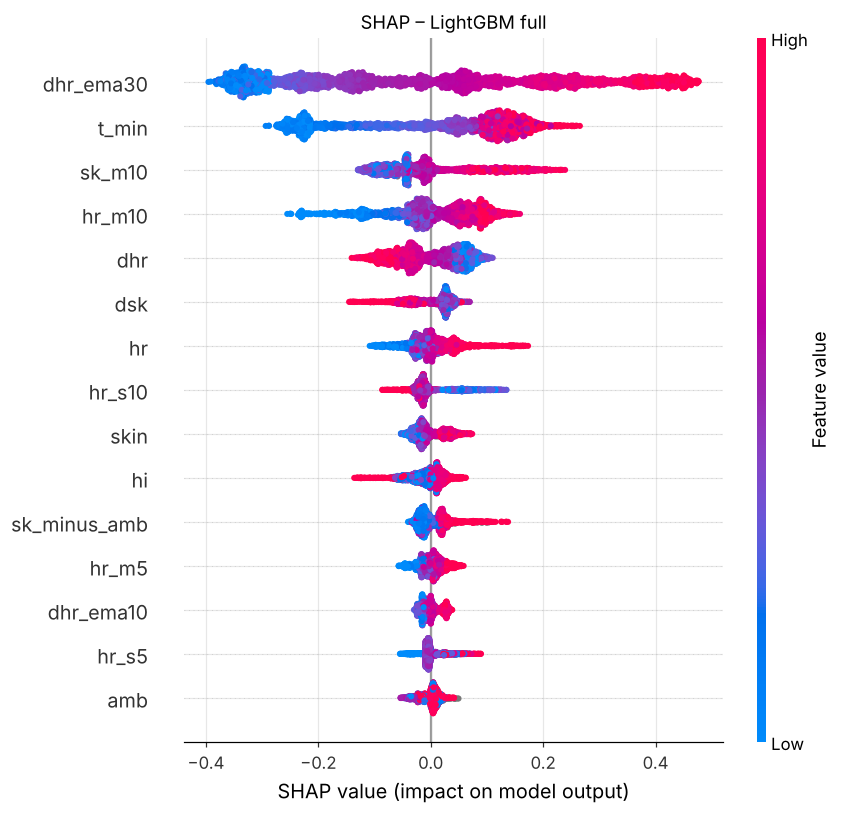

mean |SHAP| (°C):
dhr_ema30       0.2182
t_min           0.1318
sk_m10          0.0660
hr_m10          0.0625
dhr             0.0503
dsk             0.0319
hr              0.0289
hr_s10          0.0262
skin            0.0223
hi              0.0215
sk_minus_amb    0.0200
hr_m5           0.0152

Ridge full: standardised coefficients (°C per 1 SD), alpha = 100
dhr_ema30       0.4456
dhr            -0.2725
hr              0.1295
sk_m10          0.0829
dsk            -0.0812
hr_m10          0.0578
sk_minus_amb    0.0465
skin            0.0446
amb             0.0423
hr_m5           0.0326
sk_s5           0.0315
hr_s5           0.0310


In [20]:
# SHAP for the final LightGBM (or the LightGBM variant of the chosen feature set)
lgb_name = BEST if BEST.startswith("LightGBM") else ("LightGBM + ECTemp" if "ECTemp" in BEST else "LightGBM full")
lgbm = FINAL[lgb_name].best_estimator_
Xs = TB.loc[EV, MODELS[lgb_name][1]].sample(3000, random_state=SEED)
sv = shap.TreeExplainer(lgbm).shap_values(Xs)
plt.figure(); shap.summary_plot(sv, Xs, show=False, max_display=15); plt.title(f"SHAP – {lgb_name}"); plt.tight_layout()
plt.savefig(FIG/"shap_beeswarm.png", bbox_inches="tight"); plt.show()
imp = pd.Series(np.abs(sv).mean(0), index=Xs.columns).sort_values(ascending=False)
print("mean |SHAP| (°C):"); print(imp.round(4).head(12).to_string())

ridge_name = "Ridge + ECTemp" if "ECTemp" in BEST else "Ridge full"
rp = FINAL[ridge_name].best_estimator_
coef = pd.Series(rp.named_steps["ridge"].coef_, index=MODELS[ridge_name][1]).sort_values(key=np.abs, ascending=False)
print(f"\n{ridge_name}: standardised coefficients (°C per 1 SD), alpha = {rp.named_steps['ridge'].alpha}")
print(coef.round(4).head(12).to_string())

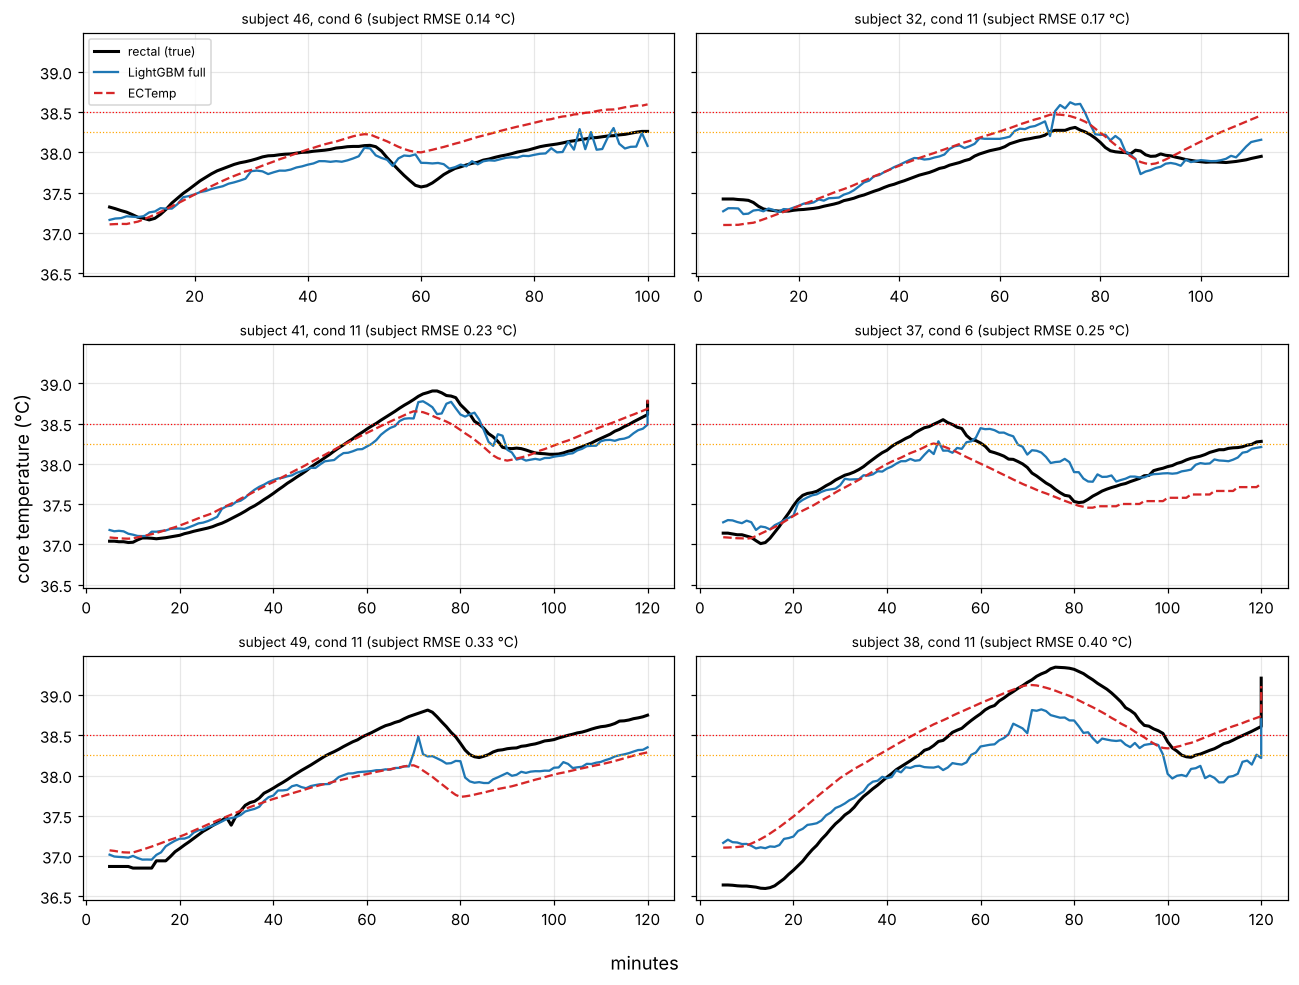

In [21]:
# Time-series examples: best, median and worst subjects for the chosen model
ev = TB[EV].assign(best=PRED[BEST][EV], ect=PRED["ECTemp (HR only)"][EV])
order_s = PS[BEST].sort_values()
pick = [order_s.index[0], order_s.index[1], order_s.index[len(order_s)//2], order_s.index[len(order_s)//2+1],
        order_s.index[-2], order_s.index[-1]]
fig, axes = plt.subplots(3, 2, figsize=(12, 9), sharey=True)
for ax, s in zip(axes.flat, pick):
    tr = ev[ev.pid == s].groupby("trial").size().idxmax(); g = ev[ev.trial == tr]
    ax.plot(g.t_min, g.y, "k", lw=2, label="rectal (true)")
    ax.plot(g.t_min, g.best, "C0", label=BEST); ax.plot(g.t_min, g.ect, "C3--", label="ECTemp")
    ax.axhline(38.5, color="r", lw=0.8, ls=":"); ax.axhline(ALARM, color="orange", lw=0.8, ls=":")
    ax.set_title(f"subject {s}, cond {int(g.cond.iloc[0])} (subject RMSE {order_s[s]:.2f} °C)", fontsize=9)
axes[0, 0].legend(fontsize=8); fig.supxlabel("minutes"); fig.supylabel("core temperature (°C)"); plt.tight_layout()
plt.savefig(FIG/"timeseries_examples.png"); plt.show()

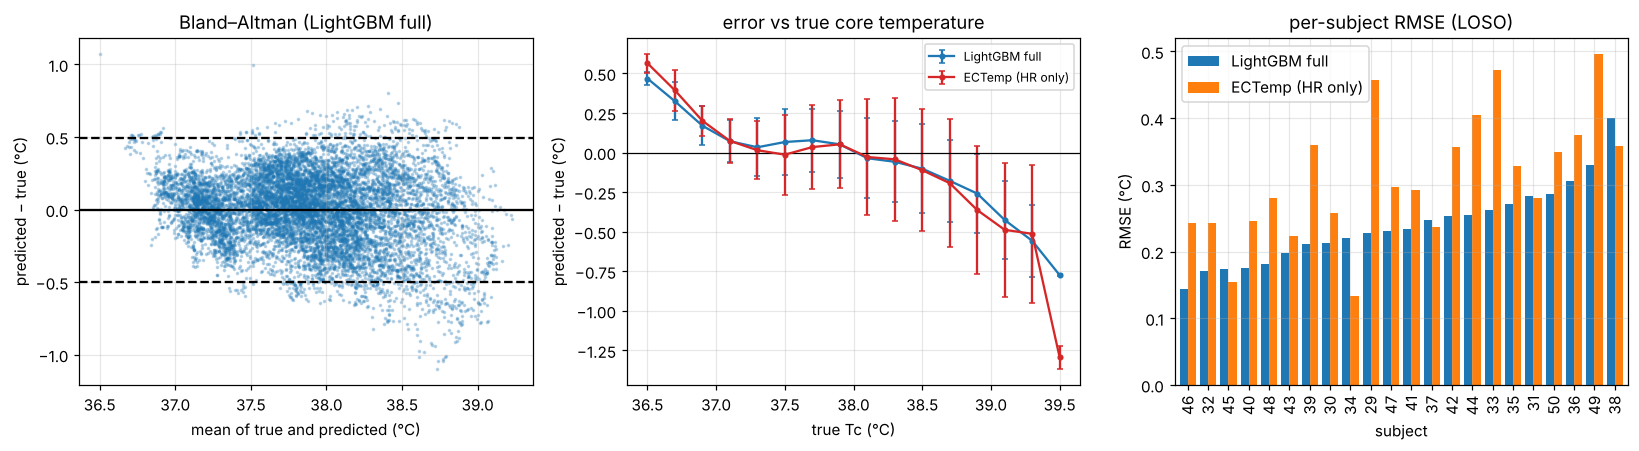

In [22]:
e = (ev.best - ev.y); mean_ = (ev.best + ev.y)/2
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
ax[0].scatter(mean_, e, s=2, alpha=0.25)
for v, ls in [(e.mean(), "-"), (e.mean()-1.96*e.std(), "--"), (e.mean()+1.96*e.std(), "--")]: ax[0].axhline(v, color="k", ls=ls)
ax[0].set(title=f"Bland–Altman ({BEST})", xlabel="mean of true and predicted (°C)", ylabel="predicted − true (°C)")
bins = np.arange(36.4, 39.8, 0.2); cut = pd.cut(ev.y, bins)
for n, c in [(BEST, "C0"), ("ECTemp (HR only)", "C3")]:
    err = (PRED[n][EV] - ev.y).groupby(cut).agg(["mean", "std"])
    ax[1].errorbar([i.mid for i in err.index], err["mean"], yerr=err["std"], color=c, marker="o", ms=3, capsize=2, label=n)
ax[1].axhline(0, color="k", lw=0.8); ax[1].legend(fontsize=8)
ax[1].set(title="error vs true core temperature", xlabel="true Tc (°C)", ylabel="predicted − true (°C)")
PS[[BEST, "ECTemp (HR only)"]].sort_values(BEST).plot.bar(ax=ax[2], width=0.8)
ax[2].set(title="per-subject RMSE (LOSO)", xlabel="subject", ylabel="RMSE (°C)")
plt.tight_layout(); plt.savefig(FIG/"bland_altman_error_persubject.png"); plt.show()

In [23]:
# Lag: shift the prediction back by k minutes and find the shift that best matches the truth
def lag_rmse(k):
    errs = []
    for _, g in ev.groupby("trial"):
        if len(g) > k + 10:
            errs.append(((g.best.values[k:] - g.y.values[:len(g)-k])**2))
    return np.sqrt(np.mean(np.concatenate(errs)))
lags = pd.Series({k: lag_rmse(k) for k in range(0, 16)})
print("RMSE vs lag (prediction compared with truth k minutes earlier):"); print(lags.round(3).to_string())
print("best-matching lag:", lags.idxmin(), "min")
# error during fast rises vs plateaus
ev["dy"] = ev.groupby("trial").y.diff(5) / 5
phase = pd.cut(ev.dy, [-1, -0.01, 0.01, 0.03, 1], labels=["falling", "flat", "slow rise", "fast rise (>0.03 °C/min)"])
display((ev.best - ev.y).groupby(phase).agg(["count", "mean", lambda x: np.sqrt(np.mean(x**2))])
        .rename(columns={"mean": "bias", "<lambda_0>": "RMSE"}).round(3))

RMSE vs lag (prediction compared with truth k minutes earlier):
0     0.252
1     0.254
2     0.258
3     0.265
4     0.274
5     0.286
6     0.298
7     0.313
8     0.328
9     0.344
10    0.361
11    0.378
12    0.395
13    0.412
14    0.429
15    0.446
best-matching lag: 0 min


,count,bias,RMSE
dy,,,
falling,1676,-0.004,0.284
flat,1643,-0.031,0.263
slow rise,4117,0.038,0.233
fast rise (>0.03 °C/min),2540,-0.046,0.259


## Save results and the deployable model

In [24]:
for n in MODELS:
    if n in THR:
        m_ = metrics(TB.y[EV], PRED[n][EV], THR[n]); LOSO.loc[n, "alarm threshold"] = THR[n]
        LOSO.loc[n, "sens_alarm"] = m_["sens_alarm"]; LOSO.loc[n, "prec_alarm"] = m_["prec_alarm"]
cols2 = cols + ["alarm threshold", "sens_alarm", "prec_alarm"]
res = pd.concat({"LOSO cohort B": LOSO.reindex(columns=cols2), "External cohort A": EXT.reindex(columns=cols2)}, names=["test", "model"])
res.round(4).to_csv(RES/"results_table.csv"); cmp.to_csv(RES/"alarm_comparison_loso.csv"); ROBT.round(4).to_csv(RES/"robustness_table.csv"); XP.round(4).to_csv(RES/"experiments_table.csv")
PS.round(4).to_csv(RES/"per_subject_rmse.csv")

bundle = {
    "model": FINAL[BEST].best_estimator_, "features": MODELS[BEST][1], "model_name": BEST,
    "nohr_model": FINAL["LightGBM no-HR"].best_estimator_, "nohr_features": F.FEATURES_NOHR,
    "feature_version": F.FEATURE_VERSION, "baseline_min": F.BASELINE_MIN,
    "alarm_threshold": ALARM, "caution_threshold": CAUTION, "nohr_alarm_threshold": THR["LightGBM no-HR"],
    "model_version": f"{BEST.replace(' ', '').replace('+','_')}-fv{F.FEATURE_VERSION}-{pd.Timestamp.now():%Y%m%d}",
    "trained_on": "PROSPIE cohort B (22 subjects, conditions 6-11), skin = upper back",
    "loso_metrics": LOSO.loc[BEST, cols2].round(4).to_dict(),
    "nohr_external_metrics": EXT.loc["LightGBM no-HR", cols].round(4).to_dict(),
}
joblib.dump(bundle, MOD/"core_temp_model.joblib")
print("saved", MOD/"core_temp_model.joblib", "->", bundle["model_version"])

saved models/core_temp_model.joblib -> LightGBMfull-fv1.0-20261010


## How each pitfall was prevented
| Pitfall | Prevention in this notebook |
|---|---|
| Leakage across subjects | Outer LOSO by subject; inner `GroupKFold(4)` by subject; imputer and scaler inside the pipeline (fitted per fold); cohort A never touched until the single external run |
| Non-causal features | `features.py` uses only past rows: carry-forward instead of interpolation, trailing rolling windows and slopes, EMAs, baseline from the first 5 min only |
| Training/serving skew | One `build_features()` used here and in `service.py`; Firebase rounding (0.1 °C, integer bpm) applied inside it; same 5-min baseline; same per-minute rows |
| Inputs not in Firebase | Only HR, one skin site, ambient T and heat index (+ derived features). RH, other skin sites, rectal T, sweat rate and perception never enter a model (age/sex/mass only in a labelled side experiment) |
| Null treated as zero | `9999` → NaN; NaN stays NaN (imputed from training medians for Ridge, native for LightGBM, skipped by ECTemp) |
| Hiding high-temperature errors | Every table reports RMSE / bias for true $T_c\ge 38.0$, sensitivity, precision and missed minutes for $T_c\ge 38.5$, plus error-vs-$T_c$ and lag plots |
| Silent assumptions | Column meanings taken from the `Key` sheet; assumptions stated in Step 0 and Step 2 |